# EDA: Phân tích tương quan giữa giá nhà và diện tích, chất lượng xây dựng

**Dữ liệu:** `cleaned.csv` (bộ dữ liệu giá nhà Ames, Iowa – 1460 dòng, 81 cột).
**Biến mục tiêu:** `SalePrice`.

**Câu hỏi nghiên cứu**
1. Các biến **diện tích** (sàn, tầng hầm, garage, lô đất…) tương quan với giá nhà ở mức nào?
2. Các biến **chất lượng xây dựng** (`OverallQual`, `ExterQual`, `KitchenQual`…) tương quan với giá nhà ra sao?
3. Diện tích và chất lượng ảnh hưởng đến giá **độc lập** hay **chồng lấn** nhau?

**Phương pháp:** Pearson (quan hệ tuyến tính), Spearman (quan hệ đơn điệu, bền với outlier), trực quan hóa (scatter, boxplot, heatmap).

## 1. Import thư viện & đọc dữ liệu

In [26]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

FIG_OUT = "../reports/figures/"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.3f}".format

df = pd.read_csv("../data/raw/train.csv")
print("Kích thước:", df.shape)
df.head()

Kích thước: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.000,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.000,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Tổng quan biến mục tiêu `SalePrice`

              count        mean        std        min         25%         50%  \
SalePrice 1,460.000 180,921.196 79,442.503 34,900.000 129,975.000 163,000.000   

                  75%         max  
SalePrice 214,000.000 755,000.000  

Skewness : 1.883
Kurtosis : 6.536


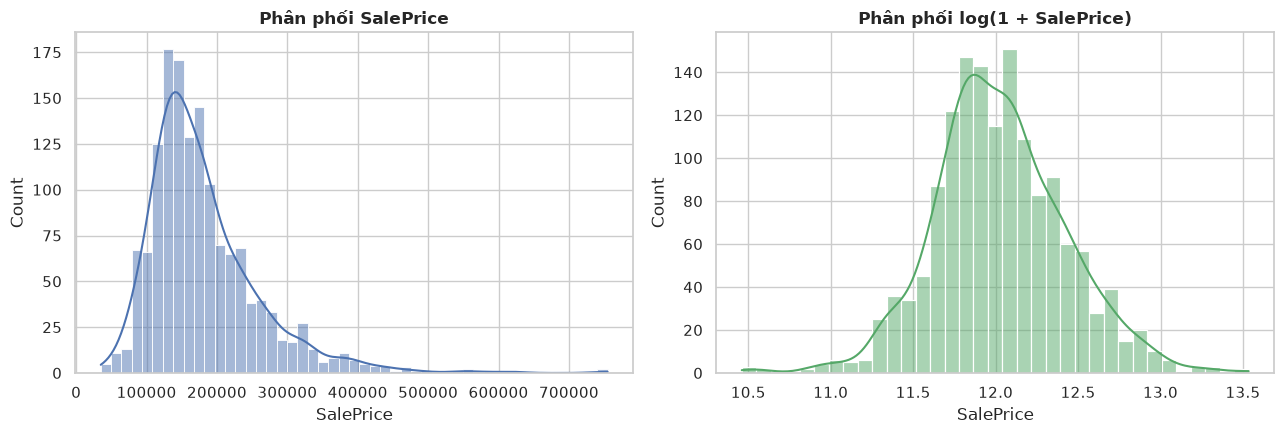

finised


<Figure size 900x500 with 0 Axes>

In [29]:
print(df["SalePrice"].describe().to_frame().T)
print(f"\nSkewness : {df['SalePrice'].skew():.3f}")
print(f"Kurtosis : {df['SalePrice'].kurt():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Phân phối SalePrice")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("Phân phối log(1 + SalePrice)")
plt.tight_layout()
plt.show()
plt.savefig("phanphoi.jpg")
print("finised")

> **Nhận xét:** `SalePrice` lệch phải rõ rệt (đuôi dài về phía nhà giá cao). Sau biến đổi log, phân phối gần chuẩn hơn.
> Vì vậy ta sẽ so sánh tương quan trên cả thang giá gốc và thang log.

## 3. Xác định nhóm biến

- **Nhóm diện tích** (biến số liên tục, đơn vị sq ft).
- **Nhóm chất lượng xây dựng:**
  - Biến số sẵn có: `OverallQual`, `OverallCond` (thang 1–10).
  - Biến thứ bậc dạng chữ (`Po < Fa < TA < Gd < Ex`) → mã hóa thành số 1–5; giá trị "không có" (`NoBasement`, `NoGarage`, …) → 0.

In [3]:
area_cols = [
    "GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GarageArea",
    "LotArea", "LotFrontage", "MasVnrArea", "BsmtFinSF1", "BsmtUnfSF",
    "WoodDeckSF", "OpenPorchSF", "PoolArea",
]

# Mã hóa các biến chất lượng dạng chữ -> số
qual_map = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ordinal_cols = ["ExterQual", "ExterCond", "BsmtQual", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

df_q = df.copy()
for c in ordinal_cols:
    df_q[c + "_num"] = df_q[c].map(qual_map).fillna(0).astype(int)   # NoXxx -> 0

quality_cols = ["OverallQual", "OverallCond"] + [c + "_num" for c in ordinal_cols]

print("Số biến diện tích :", len(area_cols))
print("Số biến chất lượng:", len(quality_cols))
df_q[ordinal_cols + [c + "_num" for c in ordinal_cols]].head()

Số biến diện tích : 13
Số biến chất lượng: 11


,ExterQual,ExterCond,BsmtQual,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC,ExterQual_num,ExterCond_num,BsmtQual_num,HeatingQC_num,KitchenQual_num,FireplaceQu_num,GarageQual_num,GarageCond_num,PoolQC_num
0,Gd,TA,Gd,Ex,Gd,NaN,TA,TA,NaN,4,3,4,5,4,0,3,3,0
1,TA,TA,Gd,Ex,TA,TA,TA,TA,NaN,3,3,4,5,3,3,3,3,0
2,Gd,TA,Gd,Ex,Gd,TA,TA,TA,NaN,4,3,4,5,4,3,3,3,0
3,TA,TA,TA,Gd,Gd,Gd,TA,TA,NaN,3,3,3,4,4,4,3,3,0
4,Gd,TA,Gd,Ex,Gd,TA,TA,TA,NaN,4,3,4,5,4,3,3,3,0


## 4. Tương quan giữa `SalePrice` và các biến diện tích

In [4]:
def corr_table(data, cols, target="SalePrice"):
    rows = []
    for c in cols:
        x, y = data[c], data[target]
        pr, pp = stats.pearsonr(x, y)
        sr, sp = stats.spearmanr(x, y)
        rows.append({"Biến": c, "Pearson r": pr, "Pearson p": pp,
                     "Spearman ρ": sr, "Spearman p": sp})
    out = pd.DataFrame(rows).set_index("Biến")
    return out.sort_values("Pearson r", ascending=False)

area_corr = corr_table(df_q, area_cols)
area_corr.style.format({"Pearson r": "{:.3f}", "Spearman ρ": "{:.3f}",
                        "Pearson p": "{:.2e}", "Spearman p": "{:.2e}"}) \
         .background_gradient(subset=["Pearson r", "Spearman ρ"], cmap="RdYlGn", vmin=-1, vmax=1)

,Pearson r,Pearson p,Spearman ρ,Spearman p
Biến,,,,
GrLivArea,0.709,4.52e-223,0.731,1.43e-244
GarageArea,0.623,5.27e-158,0.649,1.32e-175
TotalBsmtSF,0.614,9.48e-152,0.603,4.16e-145
1stFlrSF,0.606,5.39e-147,0.575,1.78e-129
BsmtFinSF1,0.386,3.39e-53,0.302,3.86e-32
WoodDeckSF,0.324,3.97e-37,0.354,2.69e-44
2ndFlrSF,0.319,5.76e-36,0.294,2.04e-30
OpenPorchSF,0.316,3.49e-35,0.478,4.86e-84
LotArea,0.264,1.12e-24,0.456,4.87e-76


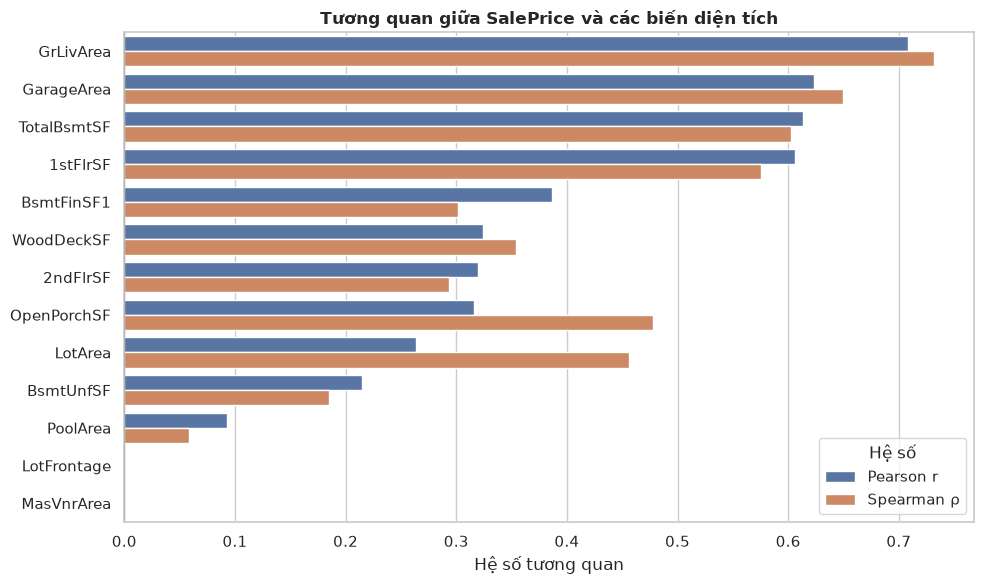

In [5]:
# Biểu đồ so sánh Pearson vs Spearman
plot_df = area_corr[["Pearson r", "Spearman ρ"]].reset_index().melt(
    id_vars="Biến", var_name="Hệ số", value_name="Giá trị")

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, y="Biến", x="Giá trị", hue="Hệ số",
            order=area_corr.index, palette=["#4C72B0", "#DD8452"])
plt.axvline(0, color="k", lw=0.8)
plt.title("Tương quan giữa SalePrice và các biến diện tích")
plt.xlabel("Hệ số tương quan"); plt.ylabel("")
plt.tight_layout(); plt.show()

> **Cách đọc mức độ (quy ước tham khảo):** |r| < 0.3 yếu · 0.3–0.5 trung bình · 0.5–0.7 khá mạnh · > 0.7 mạnh.
>
> Nếu Spearman cao hơn Pearson đáng kể ở một biến, quan hệ có thể **phi tuyến** hoặc bị **outlier / nhiều giá trị 0** làm giảm Pearson.

### 4.1 Scatter plot: giá nhà theo từng biến diện tích chính

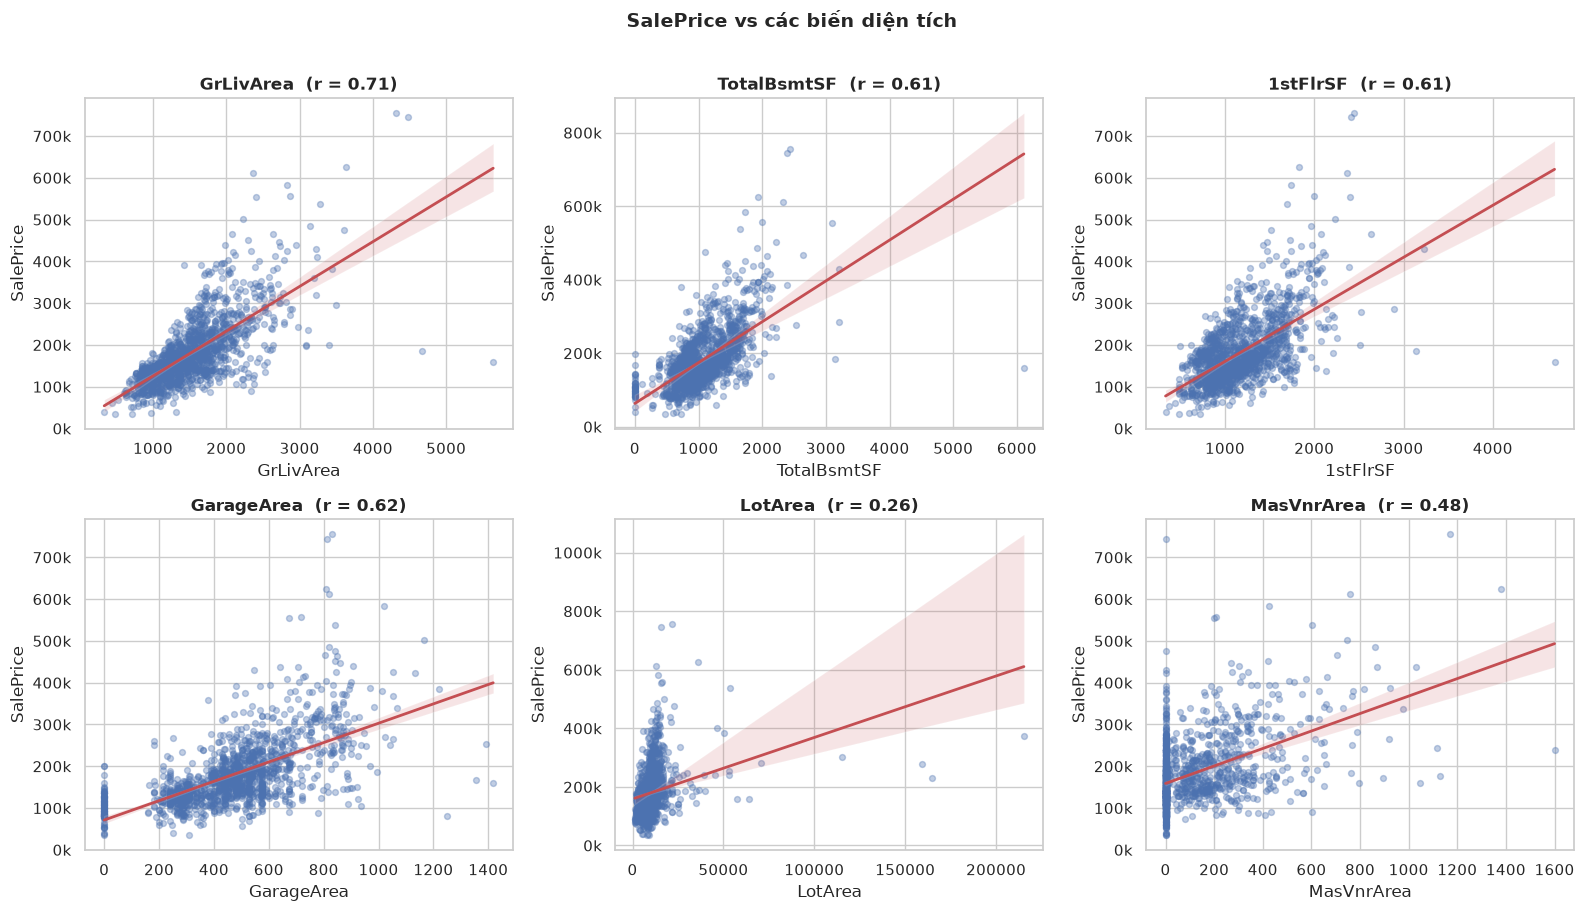

In [6]:
top_area = ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea", "LotArea", "MasVnrArea"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), top_area):
    sns.regplot(data=df_q, x=c, y="SalePrice", ax=ax,
                scatter_kws={"alpha": 0.35, "s": 18, "color": "#4C72B0"},
                line_kws={"color": "#C44E52", "lw": 2})
    r = df_q[c].corr(df_q["SalePrice"])
    ax.set_title(f"{c}  (r = {r:.2f})")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.suptitle("SalePrice vs các biến diện tích", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 4.2 Heatmap: tương quan giữa các biến diện tích (kiểm tra đa cộng tuyến)

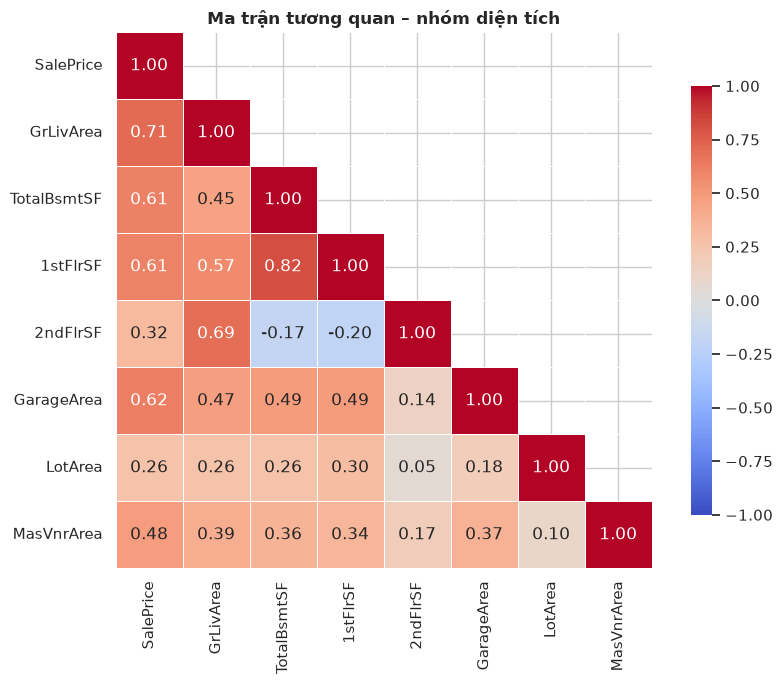

In [7]:
cols = ["SalePrice", "GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF",
        "GarageArea", "LotArea", "MasVnrArea"]
corr = df_q[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Ma trận tương quan – nhóm diện tích")
plt.tight_layout(); plt.show()

> **Lưu ý:** `GrLivArea` ≈ `1stFlrSF` + `2ndFlrSF` (+ `LowQualFinSF`), và `1stFlrSF` thường xấp xỉ `TotalBsmtSF`.
> Các biến này **tương quan mạnh với nhau**, nên khi xây mô hình hồi quy cần cân nhắc đa cộng tuyến (chọn 1 đại diện hoặc tạo biến tổng hợp như `TotalSF`).

## 5. Tương quan giữa `SalePrice` và các biến chất lượng xây dựng

In [8]:
qual_corr = corr_table(df_q, quality_cols)
qual_corr.style.format({"Pearson r": "{:.3f}", "Spearman ρ": "{:.3f}",
                        "Pearson p": "{:.2e}", "Spearman p": "{:.2e}"}) \
         .background_gradient(subset=["Pearson r", "Spearman ρ"], cmap="RdYlGn", vmin=-1, vmax=1)

,Pearson r,Pearson p,Spearman ρ,Spearman p
Biến,,,,
OverallQual,0.791,2.19e-313,0.810,0.00e+00
ExterQual_num,0.683,7.33e-201,0.684,5.61e-202
KitchenQual_num,0.660,5.05e-183,0.673,4.40e-193
BsmtQual_num,0.585,6.51e-135,0.678,3.70e-197
FireplaceQu_num,0.520,3.93e-102,0.538,3.93e-110
HeatingQC_num,0.428,5.53e-66,0.491,1.35e-89
GarageQual_num,0.274,1.59e-26,0.351,1.34e-43
GarageCond_num,0.263,1.47e-24,0.339,1.36e-40
PoolQC_num,0.112,1.89e-05,0.058,2.55e-02


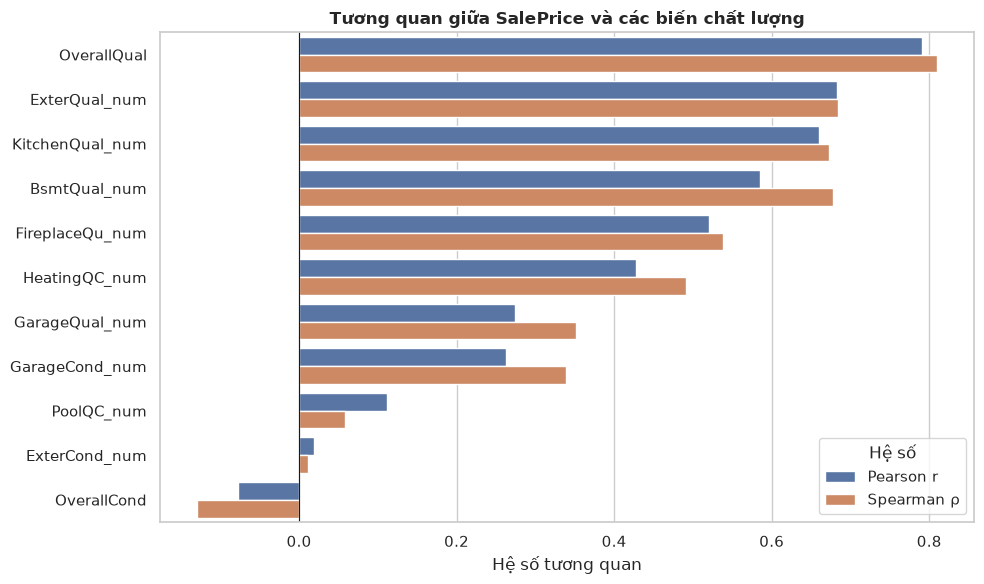

In [9]:
plot_df = qual_corr[["Pearson r", "Spearman ρ"]].reset_index().melt(
    id_vars="Biến", var_name="Hệ số", value_name="Giá trị")

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, y="Biến", x="Giá trị", hue="Hệ số",
            order=qual_corr.index, palette=["#4C72B0", "#DD8452"])
plt.axvline(0, color="k", lw=0.8)
plt.title("Tương quan giữa SalePrice và các biến chất lượng")
plt.xlabel("Hệ số tương quan"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 5.1 Giá nhà theo `OverallQual` (chất lượng tổng thể)

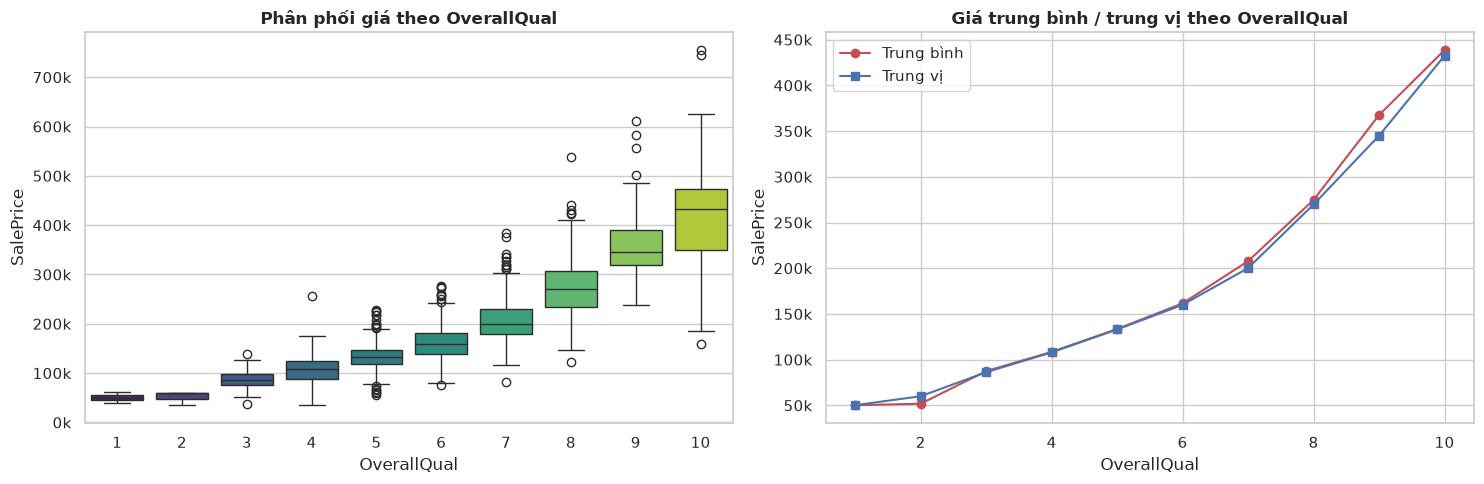

,mean,median,count
OverallQual,,,
1,"50,150.000","50,150.000",2
2,"51,770.000","60,000.000",3
3,"87,474.000","86,250.000",20
4,"108,421.000","108,000.000",116
5,"133,523.000","133,000.000",397
6,"161,603.000","160,000.000",374
7,"207,716.000","200,141.000",319
8,"274,736.000","269,750.000",168
9,"367,513.000","345,000.000",43


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df_q, x="OverallQual", y="SalePrice", ax=axes[0], palette="viridis")
axes[0].set_title("Phân phối giá theo OverallQual")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

g = df_q.groupby("OverallQual")["SalePrice"].agg(["mean", "median", "count"])
axes[1].plot(g.index, g["mean"], marker="o", label="Trung bình", color="#C44E52")
axes[1].plot(g.index, g["median"], marker="s", label="Trung vị", color="#4C72B0")
axes[1].set_title("Giá trung bình / trung vị theo OverallQual")
axes[1].set_xlabel("OverallQual"); axes[1].set_ylabel("SalePrice")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[1].legend()
plt.tight_layout(); plt.show()

g.assign(mean=g["mean"].round(0), median=g["median"].round(0))

> **Nhận xét:** Giá tăng đều và gần như **đơn điệu** theo `OverallQual`, mức tăng lớn hơn ở các bậc chất lượng cao (độ rộng boxplot cũng tăng → biến động giá lớn hơn ở phân khúc cao cấp).
> Quan hệ có dạng **cong (lồi)** hơn là đường thẳng, nên Spearman thường nhỉnh hơn Pearson.

### 5.2 Giá nhà theo các biến chất lượng dạng chữ

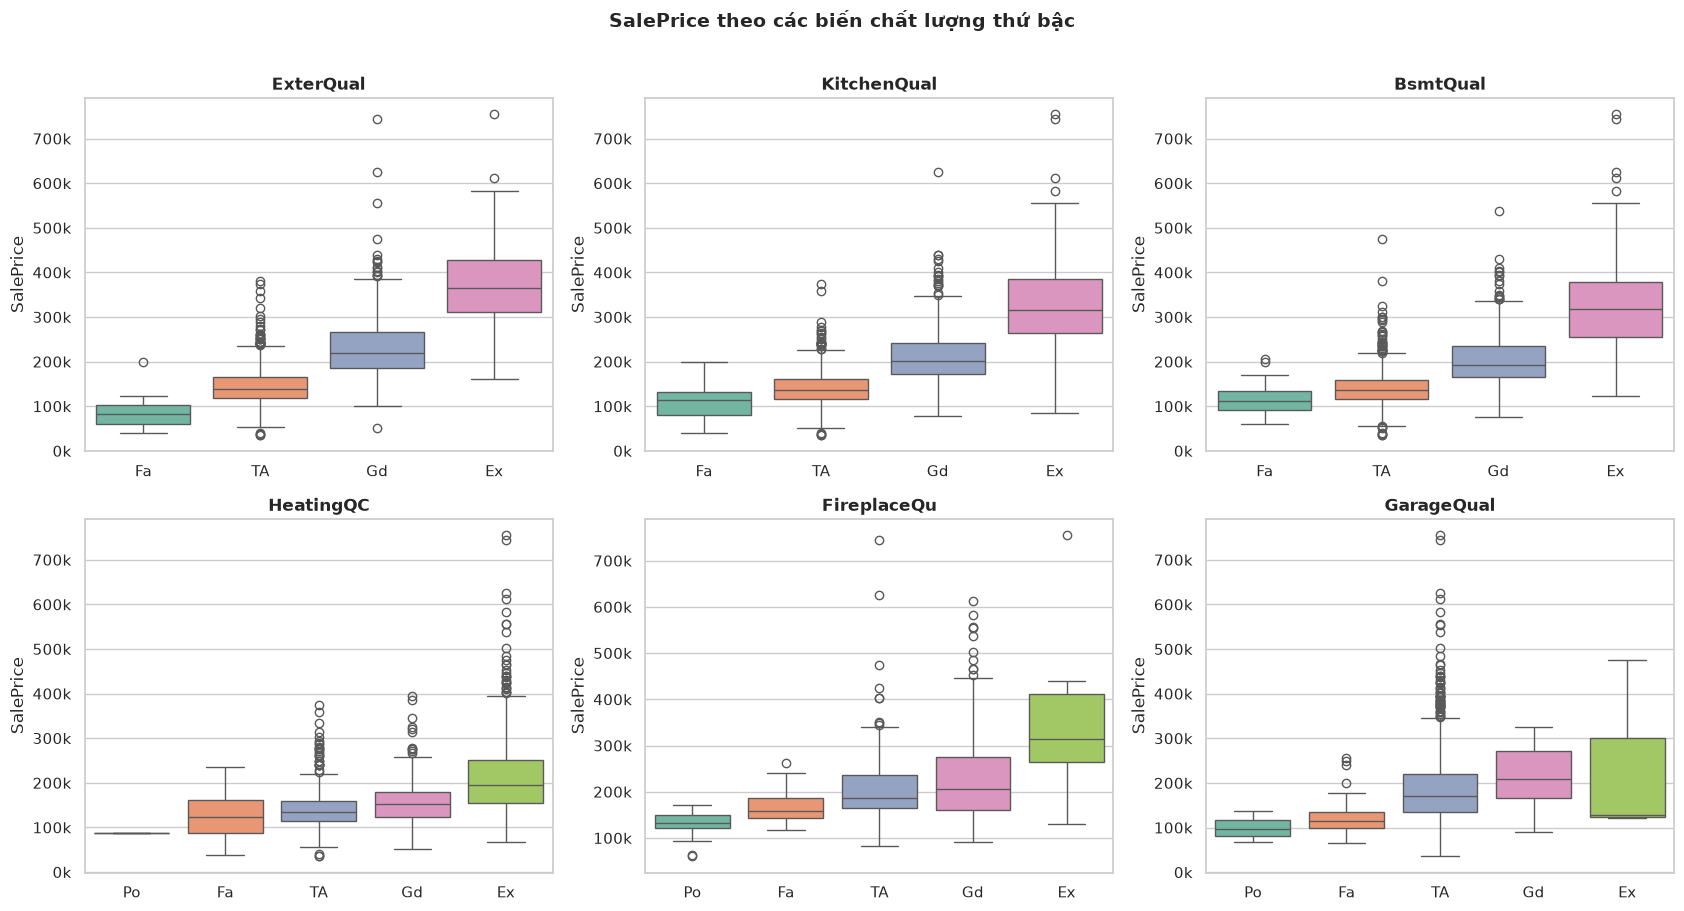

In [11]:
order = ["NoBasement", "NoGarage", "NoFireplace", "NoPool", "Po", "Fa", "TA", "Gd", "Ex"]
show = ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "FireplaceQu", "GarageQual"]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), show):
    lv = [o for o in order if o in df_q[c].unique()]
    sns.boxplot(data=df_q, x=c, y="SalePrice", order=lv, ax=ax, palette="Set2")
    ax.set_title(c); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.suptitle("SalePrice theo các biến chất lượng thứ bậc", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 5.3 Heatmap: nhóm chất lượng

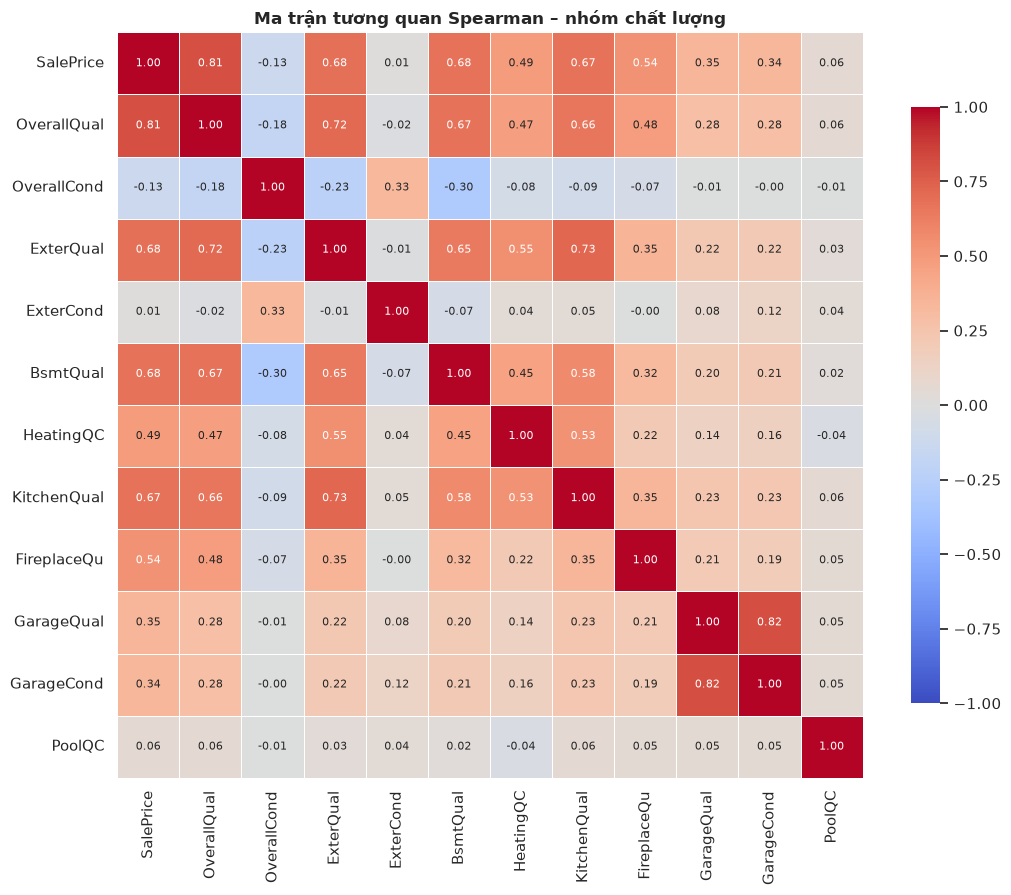

In [12]:
cols = ["SalePrice"] + quality_cols
corr = df_q[cols].corr(method="spearman")
corr.columns = [c.replace("_num", "") for c in corr.columns]
corr.index = corr.columns

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
plt.title("Ma trận tương quan Spearman – nhóm chất lượng")
plt.tight_layout(); plt.show()

## 6. So sánh: diện tích hay chất lượng ảnh hưởng đến giá mạnh hơn?

In [13]:
key_vars = ["OverallQual", "GrLivArea", "GarageArea", "TotalBsmtSF", "1stFlrSF",
            "KitchenQual_num", "ExterQual_num", "BsmtQual_num"]
cmp = corr_table(df_q, key_vars).drop(columns=["Pearson p", "Spearman p"])
cmp["Nhóm"] = np.where(cmp.index.isin(["GrLivArea", "GarageArea", "TotalBsmtSF", "1stFlrSF"]),
                       "Diện tích", "Chất lượng")
cmp["R² (Pearson)"] = cmp["Pearson r"] ** 2
cmp.sort_values("Pearson r", ascending=False)

,Pearson r,Spearman ρ,Nhóm,R² (Pearson)
Biến,,,,
OverallQual,0.791,0.810,Chất lượng,0.626
GrLivArea,0.709,0.731,Diện tích,0.502
ExterQual_num,0.683,0.684,Chất lượng,0.466
KitchenQual_num,0.660,0.673,Chất lượng,0.435
GarageArea,0.623,0.649,Diện tích,0.389
TotalBsmtSF,0.614,0.603,Diện tích,0.376
1stFlrSF,0.606,0.575,Diện tích,0.367
BsmtQual_num,0.585,0.678,Chất lượng,0.342


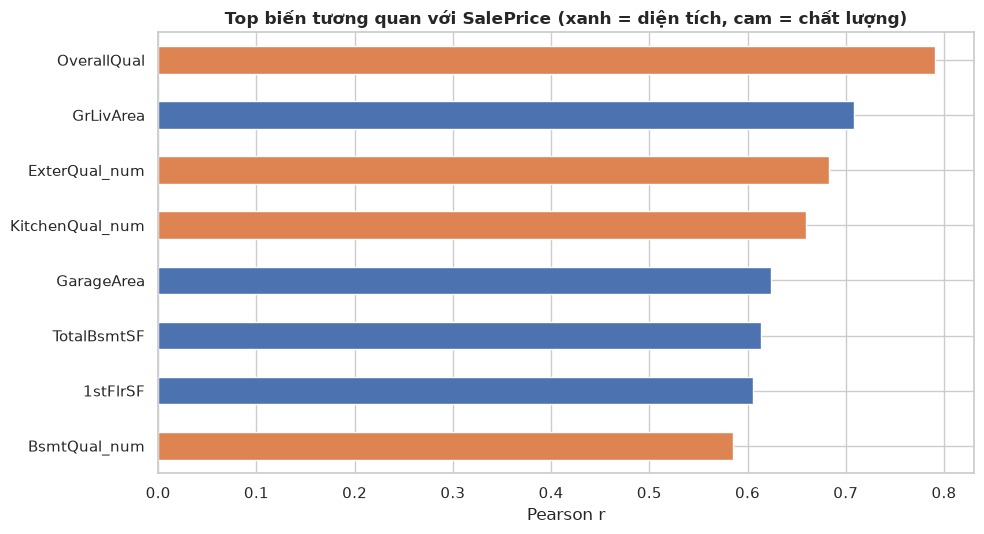

In [14]:
plt.figure(figsize=(10, 5.5))
colors = cmp.sort_values("Pearson r")["Nhóm"].map({"Diện tích": "#4C72B0", "Chất lượng": "#DD8452"})
cmp.sort_values("Pearson r")["Pearson r"].plot(kind="barh", color=colors)
plt.title("Top biến tương quan với SalePrice (xanh = diện tích, cam = chất lượng)")
plt.xlabel("Pearson r"); plt.ylabel("")
plt.tight_layout(); plt.show()

### 6.1 Diện tích và chất lượng tác động cùng nhau

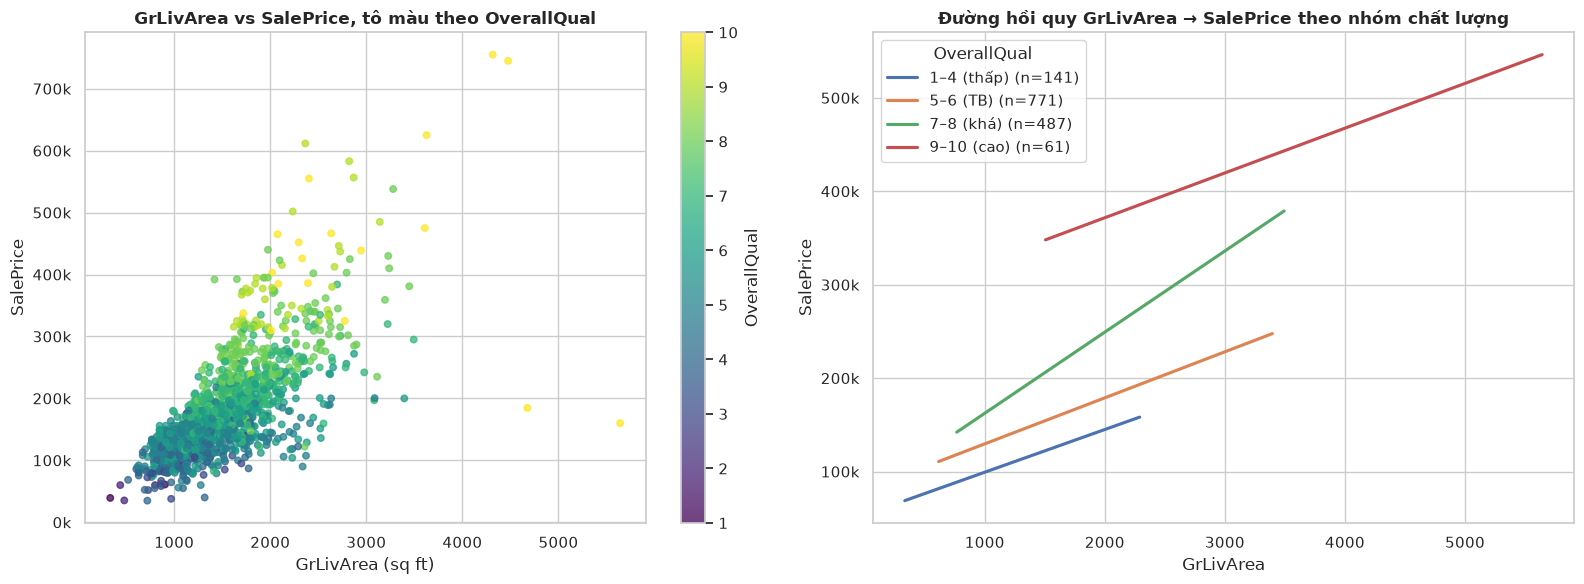

Tương quan giữa OverallQual và GrLivArea: Pearson = 0.593, Spearman = 0.603


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(df_q["GrLivArea"], df_q["SalePrice"], c=df_q["OverallQual"],
                     cmap="viridis", s=22, alpha=0.75)
plt.colorbar(sc, ax=axes[0], label="OverallQual")
axes[0].set_xlabel("GrLivArea (sq ft)"); axes[0].set_ylabel("SalePrice")
axes[0].set_title("GrLivArea vs SalePrice, tô màu theo OverallQual")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

bins = pd.cut(df_q["OverallQual"], [0, 4, 6, 8, 10], labels=["1–4 (thấp)", "5–6 (TB)", "7–8 (khá)", "9–10 (cao)"])
for lab, sub in df_q.groupby(bins):
    sns.regplot(data=sub, x="GrLivArea", y="SalePrice", scatter=False, ax=axes[1],
                label=f"{lab} (n={len(sub)})", ci=None)
axes[1].set_title("Đường hồi quy GrLivArea → SalePrice theo nhóm chất lượng")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[1].legend(title="OverallQual")
plt.tight_layout(); plt.show()

print("Tương quan giữa OverallQual và GrLivArea:",
      f"Pearson = {df_q['OverallQual'].corr(df_q['GrLivArea']):.3f},",
      f"Spearman = {df_q['OverallQual'].corr(df_q['GrLivArea'], method='spearman'):.3f}")

> **Nhận xét:** Với cùng một diện tích, nhà có `OverallQual` cao hơn có giá cao hơn rõ rệt (các đường hồi quy được tách lớp).
> Độ dốc (giá tăng thêm trên mỗi sq ft) cao nhất ở nhóm 7–8 (≈ 87 USD/sq ft, so với ≈ 46–49 ở nhóm 1–6) → có dấu hiệu **tương tác** giữa diện tích và chất lượng. Nhóm 9–10 chỉ có ~61 căn nên đường hồi quy kém ổn định, cần thận trọng khi diễn giải.
> `OverallQual` và `GrLivArea` tương quan ở mức khá (≈ 0.59: nhà lớn thường được xây tốt hơn) nên thông tin của chúng **chồng lấn một phần**.

In [16]:
# Tương quan riêng phần: ảnh hưởng của GrLivArea lên giá khi đã loại trừ OverallQual (và ngược lại)
def partial_corr(data, x, y, z):
    rx = data[x] - np.poly1d(np.polyfit(data[z], data[x], 1))(data[z])
    ry = data[y] - np.poly1d(np.polyfit(data[z], data[y], 1))(data[z])
    return np.corrcoef(rx, ry)[0, 1]

pc_area = partial_corr(df_q, "GrLivArea", "SalePrice", "OverallQual")
pc_qual = partial_corr(df_q, "OverallQual", "SalePrice", "GrLivArea")
print(f"Tương quan thô     GrLivArea ~ SalePrice    : {df_q['GrLivArea'].corr(df_q['SalePrice']):.3f}")
print(f"Tương quan riêng phần (khống chế OverallQual): {pc_area:.3f}")
print()
print(f"Tương quan thô     OverallQual ~ SalePrice  : {df_q['OverallQual'].corr(df_q['SalePrice']):.3f}")
print(f"Tương quan riêng phần (khống chế GrLivArea)  : {pc_qual:.3f}")

Tương quan thô     GrLivArea ~ SalePrice    : 0.709
Tương quan riêng phần (khống chế OverallQual): 0.486

Tương quan thô     OverallQual ~ SalePrice  : 0.791
Tương quan riêng phần (khống chế GrLivArea)  : 0.653


## 7. Outlier và độ nhạy của hệ số tương quan

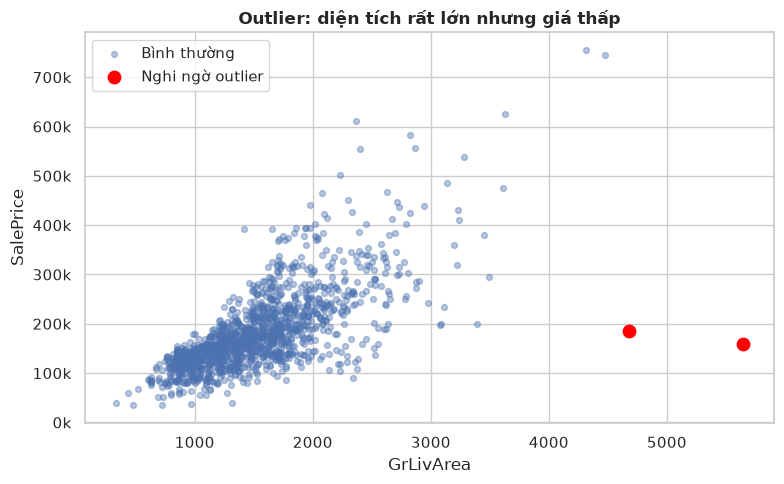

Số quan sát nghi ngờ outlier: 2


,Id,GrLivArea,TotalBsmtSF,OverallQual,SaleCondition,SalePrice
523,524,4676,3138,10,Partial,184750
1298,1299,5642,6110,10,Partial,160000


In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
out_mask = (df_q["GrLivArea"] > 4000) & (df_q["SalePrice"] < 300000)
ax.scatter(df_q.loc[~out_mask, "GrLivArea"], df_q.loc[~out_mask, "SalePrice"], s=18, alpha=0.4, label="Bình thường")
ax.scatter(df_q.loc[out_mask, "GrLivArea"], df_q.loc[out_mask, "SalePrice"], s=80, color="red", label="Nghi ngờ outlier")
ax.set_xlabel("GrLivArea"); ax.set_ylabel("SalePrice"); ax.legend()
ax.set_title("Outlier: diện tích rất lớn nhưng giá thấp")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.tight_layout(); plt.show()

print("Số quan sát nghi ngờ outlier:", out_mask.sum())
df_q.loc[out_mask, ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "SaleCondition", "SalePrice"]]

In [18]:
df_clean = df_q[~out_mask]
vars_chk = ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea", "OverallQual"]
sens = pd.DataFrame({
    "Pearson (đầy đủ)":    [df_q[c].corr(df_q["SalePrice"]) for c in vars_chk],
    "Pearson (bỏ outlier)": [df_clean[c].corr(df_clean["SalePrice"]) for c in vars_chk],
}, index=vars_chk)
sens["Chênh lệch"] = sens["Pearson (bỏ outlier)"] - sens["Pearson (đầy đủ)"]
sens

,Pearson (đầy đủ),Pearson (bỏ outlier),Chênh lệch
GrLivArea,0.709,0.735,0.026
TotalBsmtSF,0.614,0.651,0.038
1stFlrSF,0.606,0.632,0.026
GarageArea,0.623,0.629,0.006
OverallQual,0.791,0.796,0.005


> Chỉ 2 quan sát outlier nhưng đủ làm **hạ** tương quan của `GrLivArea` (0.709 → 0.735) và `TotalBsmtSF` (0.614 → 0.651); `OverallQual` gần như không bị ảnh hưởng.
> Cả hai đều là giao dịch `Partial` (nhà chưa hoàn thiện khi bán) nên có cơ sở hợp lý để loại khi mô hình hóa.

## 8. Tương quan sau khi biến đổi log

In [19]:
df_log = df_q.copy()
df_log["log_SalePrice"] = np.log1p(df_log["SalePrice"])
for c in ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "GarageArea", "LotArea"]:
    df_log["log_" + c] = np.log1p(df_log[c])

pairs = [("GrLivArea", "log_GrLivArea"), ("TotalBsmtSF", "log_TotalBsmtSF"),
         ("1stFlrSF", "log_1stFlrSF"), ("GarageArea", "log_GarageArea"),
         ("LotArea", "log_LotArea"), ("OverallQual", "OverallQual")]

res = pd.DataFrame({
    "Gốc ~ SalePrice":            [df_log[a].corr(df_log["SalePrice"]) for a, _ in pairs],
    "Gốc ~ log(SalePrice)":       [df_log[a].corr(df_log["log_SalePrice"]) for a, _ in pairs],
    "log(Biến) ~ log(SalePrice)": [df_log[b].corr(df_log["log_SalePrice"]) for _, b in pairs],
}, index=[a for a, _ in pairs])
res

,Gốc ~ SalePrice,Gốc ~ log(SalePrice),log(Biến) ~ log(SalePrice)
GrLivArea,0.709,0.701,0.730
TotalBsmtSF,0.614,0.612,0.373
1stFlrSF,0.606,0.597,0.609
GarageArea,0.623,0.651,0.455
LotArea,0.264,0.257,0.400
OverallQual,0.791,0.817,0.817


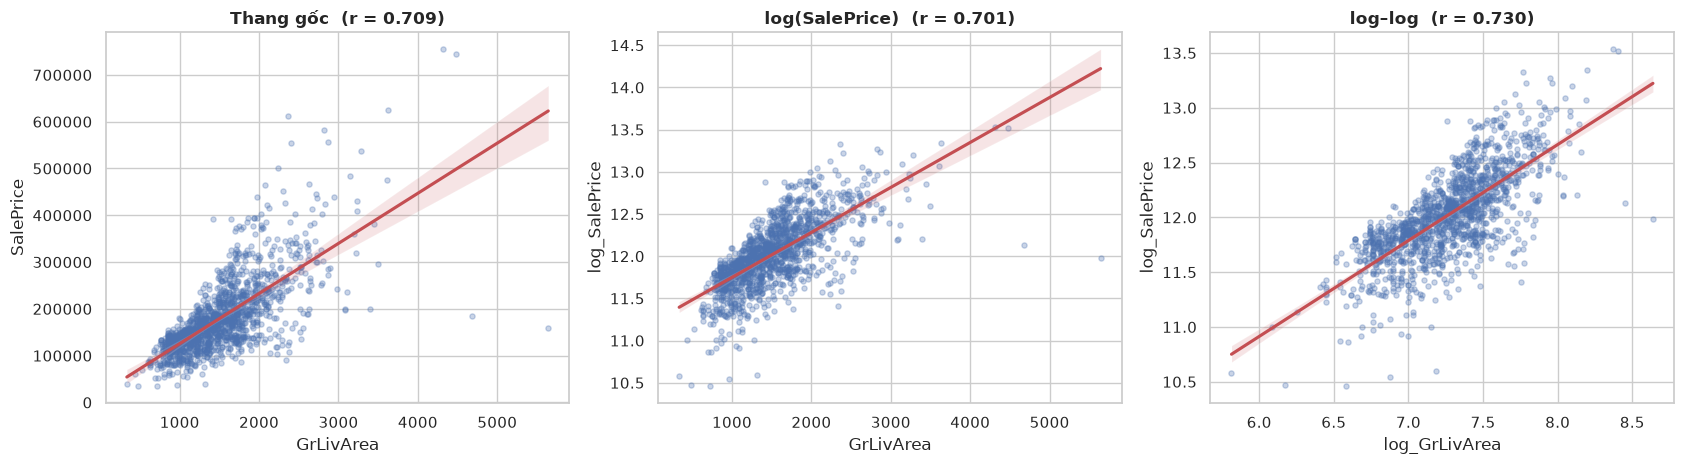

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (x, y, t) in zip(axes, [
        ("GrLivArea", "SalePrice", "Thang gốc"),
        ("GrLivArea", "log_SalePrice", "log(SalePrice)"),
        ("log_GrLivArea", "log_SalePrice", "log–log")]):
    sns.regplot(data=df_log, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.3, "s": 14},
                line_kws={"color": "#C44E52"})
    ax.set_title(f"{t}  (r = {df_log[x].corr(df_log[y]):.3f})")
plt.tight_layout(); plt.show()

> Log hóa `SalePrice` làm tăng tương quan với `OverallQual` (0.79 → 0.82) và `GarageArea`; dạng log–log cải thiện rõ với `GrLivArea` (0.71 → 0.73) và `LotArea` (0.26 → 0.40).
> **Lưu ý:** với `TotalBsmtSF` và `GarageArea`, log–log lại *làm giảm* tương quan vì nhiều căn có giá trị 0 (không có hầm/garage) bị kéo thành `log1p(0)=0` tạo cụm điểm lệch. Không nên log hóa máy móc mọi biến diện tích.

## 9. Kiểm định ý nghĩa thống kê và kích thước hiệu ứng

In [21]:
# 9.1 Kruskal-Wallis: giá có khác nhau giữa các mức OverallQual không?
groups = [g["SalePrice"].values for _, g in df_q.groupby("OverallQual")]
H, p = stats.kruskal(*groups)
n, k = len(df_q), len(groups)
eps2 = (H - k + 1) / (n - k)      # epsilon-squared (kích thước hiệu ứng)
print(f"Kruskal-Wallis (SalePrice ~ OverallQual): H = {H:.1f}, p = {p:.2e}, ε² = {eps2:.3f}")

# 9.2 Khoảng tin cậy 95% (bootstrap) cho Pearson r
def boot_ci(x, y, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(x)); rs = []
    for _ in range(B):
        s = rng.choice(idx, len(idx), replace=True)
        rs.append(np.corrcoef(x.iloc[s], y.iloc[s])[0, 1])
    return np.percentile(rs, [2.5, 97.5])

rows = []
for c in ["OverallQual", "GrLivArea", "GarageArea", "TotalBsmtSF", "1stFlrSF", "KitchenQual_num", "ExterQual_num"]:
    lo, hi = boot_ci(df_q[c], df_q["SalePrice"])
    rows.append({"Biến": c, "Pearson r": df_q[c].corr(df_q["SalePrice"]), "CI 95% thấp": lo, "CI 95% cao": hi})
pd.DataFrame(rows).set_index("Biến").sort_values("Pearson r", ascending=False)

Kruskal-Wallis (SalePrice ~ OverallQual): H = 966.1, p = 3.51e-202, ε² = 0.660


,Pearson r,CI 95% thấp,CI 95% cao
Biến,,,
OverallQual,0.791,0.773,0.811
GrLivArea,0.709,0.659,0.756
ExterQual_num,0.683,0.649,0.716
KitchenQual_num,0.660,0.630,0.689
GarageArea,0.623,0.588,0.658
TotalBsmtSF,0.614,0.544,0.673
1stFlrSF,0.606,0.554,0.655


## 10. Kết luận

**Diện tích**
- `GrLivArea` (diện tích sinh hoạt trên mặt đất) là biến diện tích tương quan mạnh nhất với giá (Pearson ≈ 0.71, CI 95% ≈ 0.66–0.76).
- Tiếp theo là `GarageArea`, `TotalBsmtSF`, `1stFlrSF` (≈ 0.6–0.62) – mức khá mạnh.
- `LotArea`, `LotFrontage`, `WoodDeckSF`, `OpenPorchSF` chỉ ở mức yếu – trung bình (≈ 0.26–0.35); `PoolArea` gần như không đáng kể.
- Các biến diện tích **tương quan mạnh với nhau** (đa cộng tuyến) → nên chọn biến đại diện hoặc tạo biến tổng hợp (vd. `TotalSF`).

**Chất lượng xây dựng**
- `OverallQual` là biến tương quan mạnh nhất trong toàn nhóm (Pearson ≈ 0.79, Spearman ≈ 0.81), thậm chí cao hơn mọi biến diện tích.
- `ExterQual` (≈ 0.68), `KitchenQual` (≈ 0.66), `BsmtQual` (≈ 0.59 Pearson, 0.68 Spearman) cũng tương quan khá mạnh; `OverallCond` (tình trạng) **gần như không** liên quan đến giá – chất lượng vật liệu/hoàn thiện quan trọng hơn mức độ bảo dưỡng.

**Tổng hợp & gợi ý cho bước mô hình hóa**
1. Chất lượng (`OverallQual`) và diện tích (`GrLivArea`) đều là các yếu tố dự báo giá hàng đầu, nhưng **chồng lấn một phần**: khi khống chế biến còn lại, tương quan của `GrLivArea` giảm 0.71 → 0.49, của `OverallQual` giảm 0.79 → 0.65. Chất lượng giữ được sức giải thích riêng lớn hơn.
2. Có dấu hiệu **tương tác** diện tích × chất lượng: mỗi sq ft tăng thêm làm giá tăng nhiều hơn ở nhóm `OverallQual` 7–8 so với nhóm thấp hơn.
3. Nên cân nhắc: biến đổi log cho `SalePrice` và các biến diện tích, xử lý 2 outlier `Partial` (`GrLivArea` > 4000 sq ft, giá thấp), chỉ log hóa các biến không chứa nhiều giá trị 0, thêm biến tương tác `OverallQual × GrLivArea`.
4. Lưu ý: tương quan **không phải quan hệ nhân quả** – ví dụ nhà đắt hơn có thể vừa lớn hơn vừa được xây tốt hơn do vị trí/phân khúc (`Neighborhood`).